# 03 - Preprocessing & Anomaly Detection

Handle missing values, remove duplicates, detect and remove outliers using IQR method, scale features, and create train/test split.

In [1]:
# Setup
import sys
sys.path.append('../')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data.ingestion import load_raw_data
from src.data.preprocessing import (
    handle_missing_values,
    remove_duplicates,
    detect_outliers_iqr,
    remove_outliers,
    convert_date_features,
    scale_features,
    prepare_features_target,
    stratified_train_test_split,
    full_preprocessing_pipeline
)
from src.config import DATA_PROCESSED

In [2]:
# Load raw data
df = load_raw_data()
print(f"Raw data shape: {df.shape}")
print(f"Missing values:\n{df.isnull().sum()[df.isnull().sum() > 0]}")

Loading data from: /Users/premkumarreddy/projects/real estate/notebooks/../data/raw/kc_house_data.csv
Loaded 21613 rows, 21 columns
Raw data shape: (21613, 21)
Missing values:
Series([], dtype: int64)


In [3]:
# 1. Handle Missing Values
print("=== 1. Handling Missing Values ===")
df_clean = handle_missing_values(df)
print(f"Missing values after handling: {df_clean.isnull().sum().sum()}")

=== 1. Handling Missing Values ===
Missing values after handling: 0


In [4]:
# 2. Remove Duplicates
print("=== 2. Removing Duplicates ===")
df_clean = remove_duplicates(df_clean, subset=['id'])
print(f"Shape after dedup: {df_clean.shape}")

=== 2. Removing Duplicates ===
Removed 177 duplicate rows
Shape after dedup: (21436, 21)


In [5]:
# 3. Convert Date Features
print("=== 3. Converting Date Features ===")
df_clean = convert_date_features(df_clean)
print(f"Date features added: sale_year, sale_month, sale_quarter, sale_dayofweek")
print(df_clean[['date', 'sale_year', 'sale_month', 'sale_quarter']].head())

=== 3. Converting Date Features ===
Date features added: sale_year, sale_month, sale_quarter, sale_dayofweek
        date  sale_year  sale_month  sale_quarter
0 2014-10-13       2014          10             4
1 2014-12-09       2014          12             4
2 2015-02-25       2015           2             1
3 2014-12-09       2014          12             4
4 2015-02-18       2015           2             1


In [6]:
# 4. Outlier Detection (IQR Method)
print("=== 4. Outlier Detection ===")
outlier_columns = ['price', 'sqft_living', 'sqft_lot', 'sqft_above', 'sqft_basement', 'sqft_living15', 'sqft_lot15']
outlier_flags = detect_outliers_iqr(df_clean, outlier_columns, factor=1.5)

# Summary of outliers
outlier_summary = {}
for col in outlier_columns:
    flag_col = f"{col}_outlier"
    if flag_col in outlier_flags.columns:
        n = outlier_flags[flag_col].sum()
        pct = n / len(df_clean) * 100
        outlier_summary[col] = {'count': n, 'percentage': pct}
        print(f"  {col}: {n} outliers ({pct:.2f}%)")

=== 4. Outlier Detection ===
price: 1139 outliers detected (bounds: -162125.00, 1129275.00)
sqft_living: 569 outliers detected (bounds: -250.00, 4230.00)
sqft_lot: 2409 outliers detected (bounds: -3444.38, 19180.62)
sqft_above: 601 outliers detected (bounds: -330.00, 3750.00)
sqft_basement: 493 outliers detected (bounds: -840.00, 1400.00)
sqft_living15: 504 outliers detected (bounds: 170.00, 3690.00)
sqft_lot15: 2180 outliers detected (bounds: -2380.88, 17568.12)
  price: 1139 outliers (5.31%)
  sqft_living: 569 outliers (2.65%)
  sqft_lot: 2409 outliers (11.24%)
  sqft_above: 601 outliers (2.80%)
  sqft_basement: 493 outliers (2.30%)
  sqft_living15: 504 outliers (2.35%)
  sqft_lot15: 2180 outliers (10.17%)


/var/folders/c0/k0_js5dx7zdfs4gb0h07klwm0000gn/T/ipykernel_3586/3300637351.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df_clean[col].dropna(), vert=True)
/var/folders/c0/k0_js5dx7zdfs4gb0h07klwm0000gn/T/ipykernel_3586/3300637351.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df_clean[col].dropna(), vert=True)
/var/folders/c0/k0_js5dx7zdfs4gb0h07klwm0000gn/T/ipykernel_3586/3300637351.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df_clean[col].dropna(), vert=True)
/var/folders/c0/k0_js5dx7zdfs4gb0h07klwm0000gn/T/ipykernel_3586/3300637351.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Ma

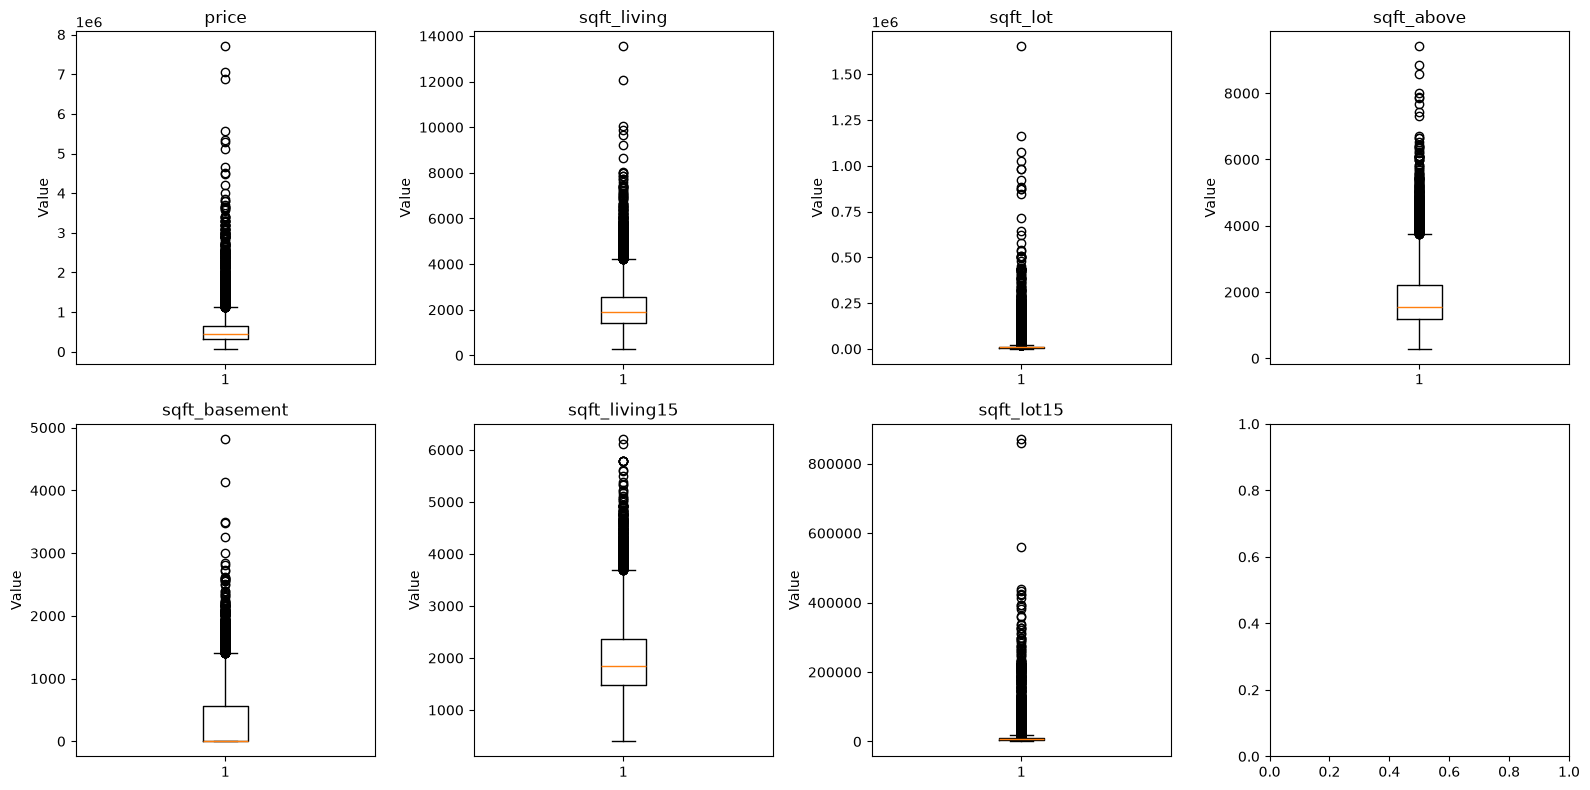

In [7]:
# Visualize outliers for key columns
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, col in enumerate(outlier_columns):
    ax = axes[idx]
    ax.boxplot(df_clean[col].dropna(), vert=True)
    ax.set_title(f'{col}')
    ax.set_ylabel('Value')

plt.tight_layout()
plt.show()

In [8]:
# 5. Remove Outliers
print("=== 5. Removing Outliers ===")
df_clean = remove_outliers(df_clean, outlier_flags, outlier_columns)
print(f"Shape after outlier removal: {df_clean.shape}")

=== 5. Removing Outliers ===
Removed 3922 rows with outliers (18.30% of data)
Shape after outlier removal: (17514, 25)


In [9]:
# 6. Prepare Features and Target
print("=== 6. Preparing Features and Target ===")
from src.config import TARGET, DROP_FEATURES

X, y = prepare_features_target(df_clean, target=TARGET, drop_features=DROP_FEATURES)
print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"\nFeature columns: {list(X.columns)}")

=== 6. Preparing Features and Target ===
Features shape: (17514, 23)
Target shape: (17514,)

Feature columns: ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'sale_quarter', 'sale_dayofweek']


In [10]:
# 7. Stratified Train/Test Split
print("=== 7. Train/Test Split ===")
X_train, X_test, y_train, y_test = stratified_train_test_split(X, y)

# Check target distribution in both sets
print(f"\nTrain price stats:")
print(y_train.describe())
print(f"\nTest price stats:")
print(y_test.describe())

=== 7. Train/Test Split ===
Train set: 14011 samples
Test set: 3503 samples

Train price stats:
count    1.401100e+04
mean     4.592252e+05
std      1.978094e+05
min      7.800000e+04
25%      3.055000e+05
50%      4.230000e+05
75%      5.750000e+05
max      1.127000e+06
Name: price, dtype: float64

Test price stats:
count    3.503000e+03
mean     4.592108e+05
std      1.980087e+05
min      8.900000e+04
25%      3.070000e+05
50%      4.228000e+05
75%      5.790500e+05
max      1.125000e+06
Name: price, dtype: float64


In [11]:
# 8. Feature Scaling
print("=== 8. Feature Scaling ===")
numerical_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
print(f"Scaling {len(numerical_cols)} numerical columns")

X_train_scaled, X_test_scaled, scaler = scale_features(
    X_train, X_test, scaler_type='standard', columns=numerical_cols
)

print(f"\nTrain scaled stats (first 5 cols):")
print(X_train_scaled[numerical_cols[:5]].describe().round(3))
print(f"\nTest scaled stats (first 5 cols):")
print(X_test_scaled[numerical_cols[:5]].describe().round(3))

=== 8. Feature Scaling ===
Scaling 23 numerical columns

Train scaled stats (first 5 cols):
           price   bedrooms  bathrooms  sqft_living   sqft_lot
count  14011.000  14011.000  14011.000    14011.000  14011.000
mean       0.000     -0.000      0.000       -0.000      0.000
std        1.000      1.000      1.000        1.000      1.000
min       -1.927     -3.638     -2.928       -2.235     -1.914
25%       -0.777     -0.319     -0.739       -0.754     -0.683
50%       -0.183     -0.319     -0.010       -0.125     -0.014
75%        0.585      0.787      0.720        0.654      0.571
max        3.376     32.867      5.462        3.498      3.505

Test scaled stats (first 5 cols):
          price  bedrooms  bathrooms  sqft_living  sqft_lot
count  3503.000  3503.000   3503.000     3503.000  3503.000
mean     -0.000     0.002     -0.009        0.021    -0.012
std       1.001     0.976      0.991        0.994     0.976
min      -1.872    -3.638     -2.928       -2.101    -1.899
25%   

In [12]:
# 9. Save Processed Data
print("=== 9. Saving Processed Data ===")
from src.data.preprocessing import save_processed_data

save_processed_data(X_train_scaled, X_test_scaled, y_train, y_test, scaler)
print("Processed data saved successfully!")

=== 9. Saving Processed Data ===


Processed data saved to: /Users/premkumarreddy/projects/real estate/notebooks/../data/processed
Processed data saved successfully!


In [13]:
# 10. Verify Saved Data
print("=== 10. Verification ===")
from src.data.preprocessing import load_processed_data

X_train_v, X_test_v, y_train_v, y_test_v, scaler_v = load_processed_data()
print(f"Loaded train: {X_train_v.shape}")
print(f"Loaded test: {X_test_v.shape}")
print(f"Scaler type: {type(scaler_v).__name__}")

=== 10. Verification ===
Loaded train: (14011, 23)
Loaded test: (3503, 23)
Scaler type: StandardScaler


In [14]:
# Alternative: Run Full Pipeline
print("=== Alternative: Full Pipeline ===")
# Uncomment to run full pipeline from scratch
# X_train, X_test, y_train, y_test, scaler = full_preprocessing_pipeline(df)

=== Alternative: Full Pipeline ===
